Executing on Device: cuda
Training Baseline...
Epoch 1/10 | Train Loss (CE): 3.7225 | Val Acc: 19.19%
Epoch 2/10 | Train Loss (CE): 2.9051 | Val Acc: 31.37%
Epoch 3/10 | Train Loss (CE): 2.3294 | Val Acc: 40.48%
Epoch 4/10 | Train Loss (CE): 1.9514 | Val Acc: 45.77%
Epoch 5/10 | Train Loss (CE): 1.6794 | Val Acc: 52.18%
Epoch 6/10 | Train Loss (CE): 1.4383 | Val Acc: 57.26%
Epoch 7/10 | Train Loss (CE): 1.2288 | Val Acc: 61.49%
Epoch 8/10 | Train Loss (CE): 1.0400 | Val Acc: 65.38%
Epoch 9/10 | Train Loss (CE): 0.8970 | Val Acc: 66.67%
Epoch 10/10 | Train Loss (CE): 0.8167 | Val Acc: 66.81%

Training Modified Model...
Epoch 1/10 | Train Loss (CE): 3.5276 | Val Acc: 24.13%
Epoch 2/10 | Train Loss (CE): 2.5792 | Val Acc: 34.70%
Epoch 3/10 | Train Loss (CE): 2.0699 | Val Acc: 37.47%
Epoch 4/10 | Train Loss (CE): 1.7681 | Val Acc: 46.21%
Epoch 5/10 | Train Loss (CE): 1.5877 | Val Acc: 31.66%
Epoch 6/10 | Train Loss (CE): 1.4461 | Val Acc: 17.16%
Epoch 7/10 | Train Loss (CE): 1.3503 | Val A

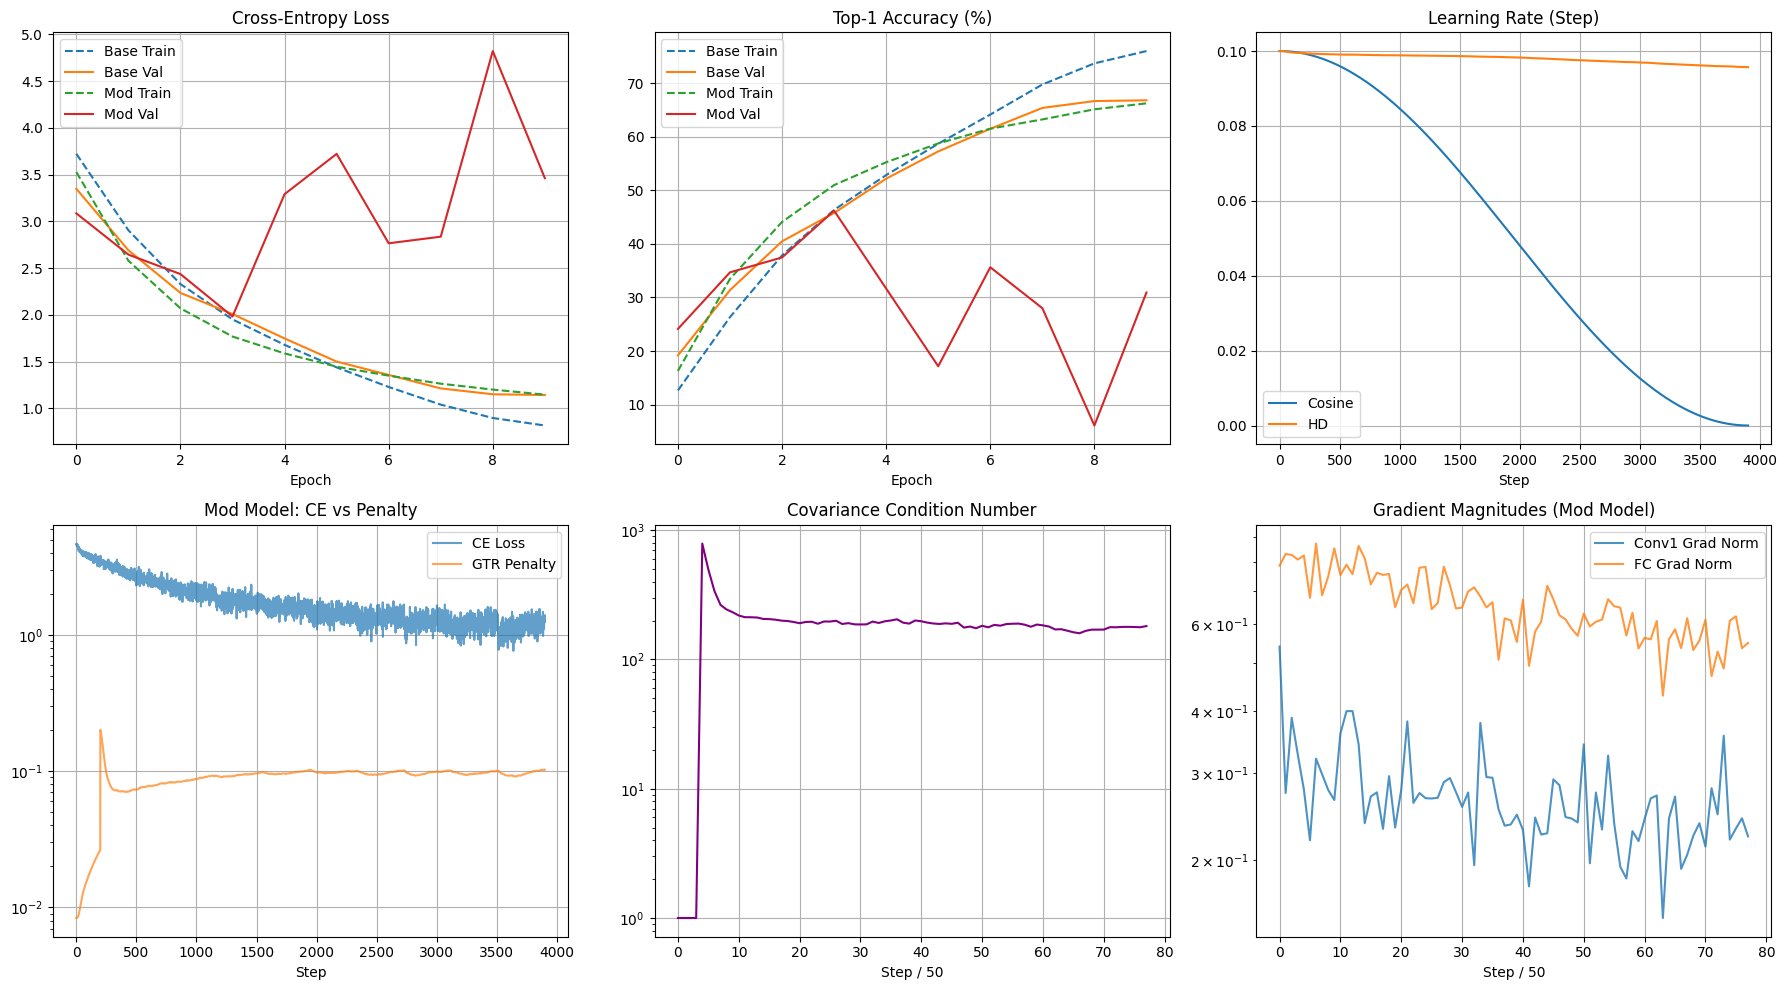

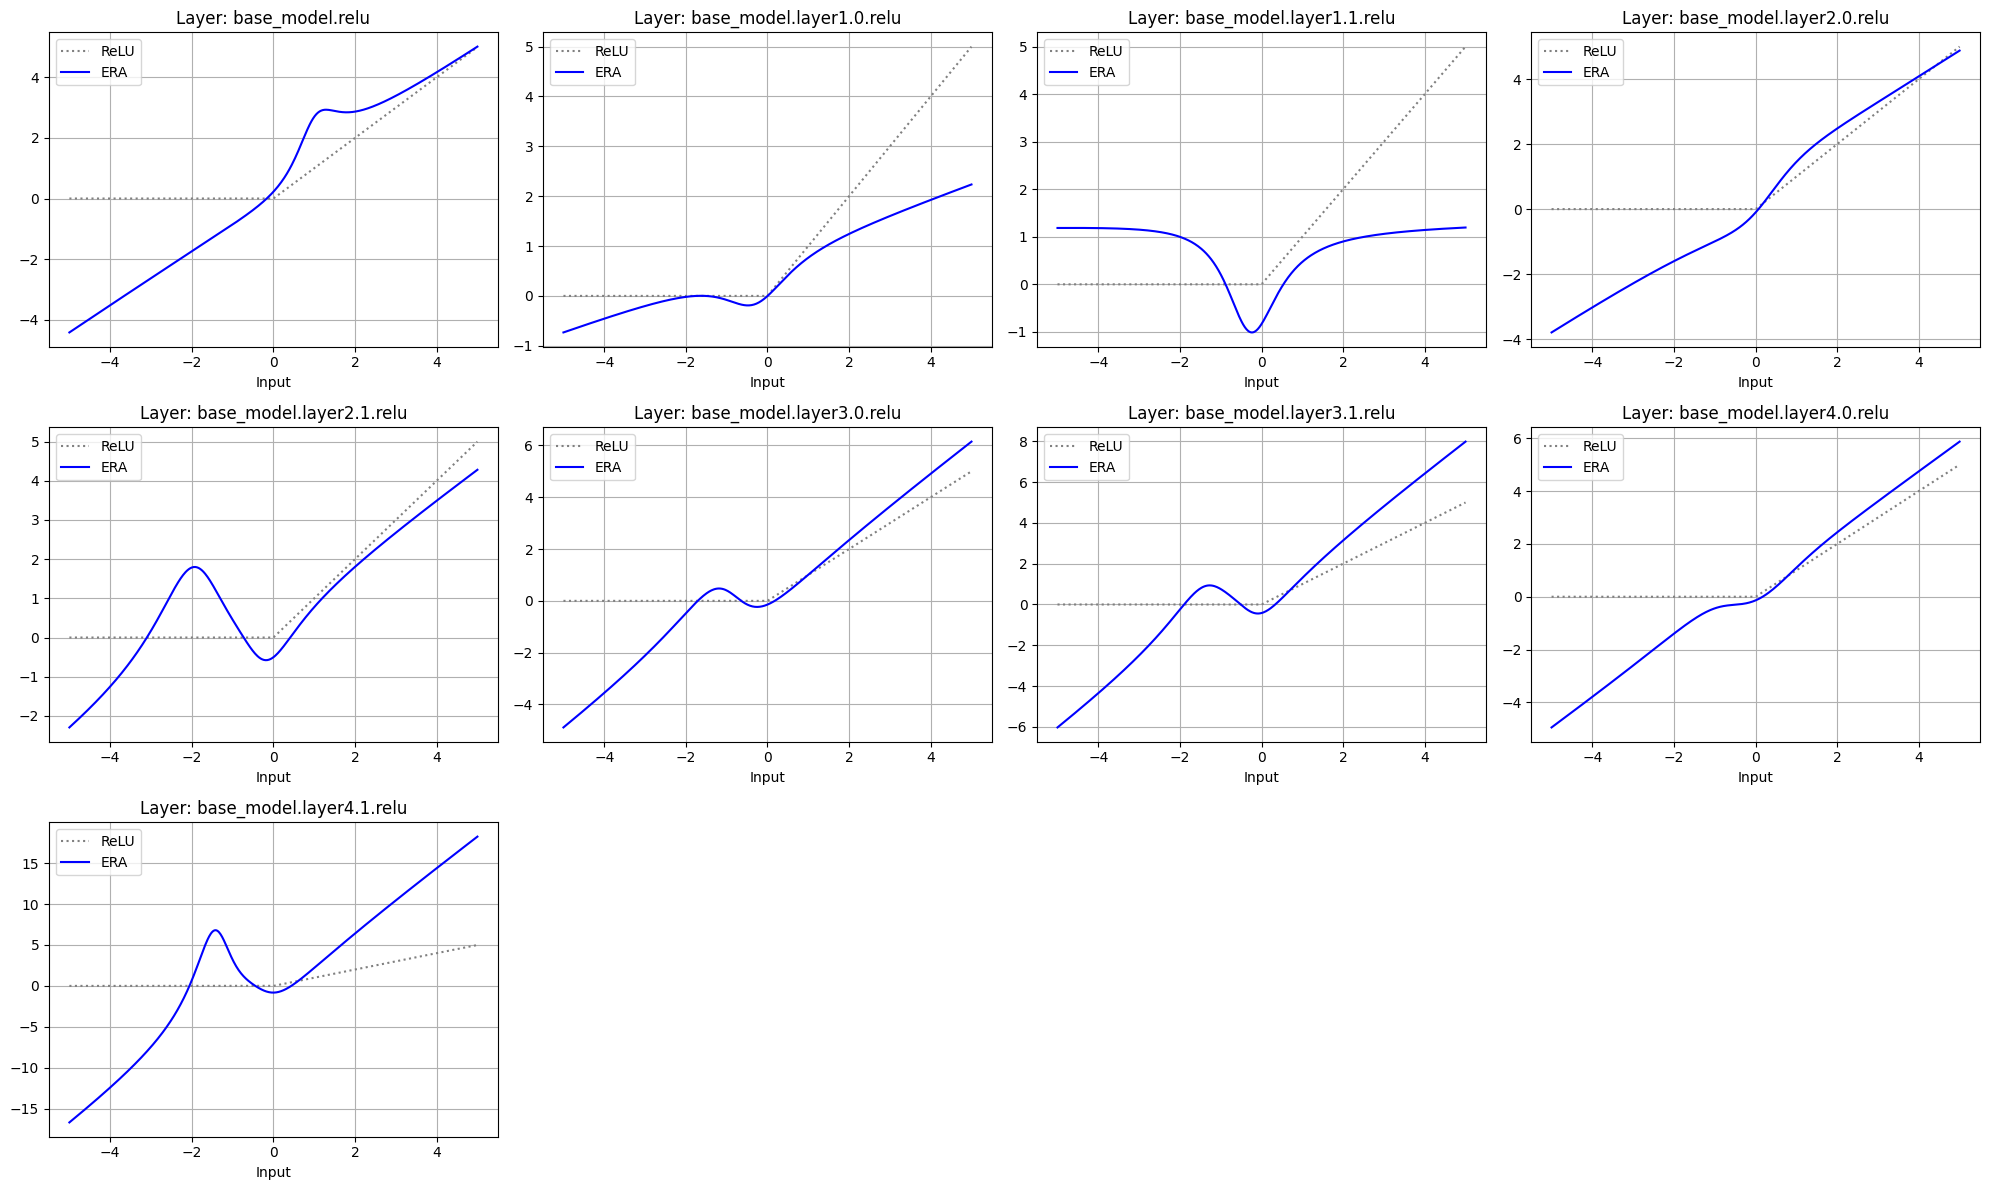

In [10]:
import copy
import math
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURATION
# ==========================================
DEBUG_MODE = False

# ==========================================
# 1. Layer-wise Enhanced Rational Activation (ERA)
# ==========================================
class LayerERA(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(1.0))
        self.b = nn.Parameter(torch.tensor(0.0))
        self.c = nn.Parameter(torch.randn(2) * 0.1)
        self.d = nn.Parameter(torch.randn(2) * 0.1)
        self.e = nn.Parameter(torch.randn(2))
        self.f = nn.Parameter(torch.ones(2)) 
        
        self._initialize_to_swish()

    def _initialize_to_swish(self):
        optimizer = optim.Adam(self.parameters(), lr=0.05)
        x = torch.linspace(-5, 5, 1000).view(-1, 1)
        y_target = x * torch.sigmoid(x)
        
        for _ in range(500):
            optimizer.zero_grad()
            y_pred = self.forward(x)
            loss = nn.functional.mse_loss(y_pred, y_target)
            loss.backward()
            optimizer.step()

    def forward(self, x):
        term1 = (self.c[0] * x + self.d[0]) / ((x - self.e[0])**2 + self.f[0]**2 + 1e-6)
        term2 = (self.c[1] * x + self.d[1]) / ((x - self.e[1])**2 + self.f[1]**2 + 1e-6)
        return self.a * x + self.b + term1 + term2

# ==========================================
# 2. Hypergradient Descent Optimizer
# ==========================================
class SGDHD(optim.SGD):
    def __init__(self, params, lr=0.1, hyper_lr=1e-5, **kwargs):
        super().__init__(params, lr=lr, **kwargs)
        self.hyper_lr = hyper_lr

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            loss = closure()

        dot_product = 0.0
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if 'prev_grad' in state:
                    dot_product += torch.sum(p.grad * state['prev_grad']).item()

        for group in self.param_groups:
            new_lr = group['lr'] + self.hyper_lr * dot_product
            group['lr'] = max(1e-6, min(0.5, new_lr))

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                self.state[p]['prev_grad'] = p.grad.clone()

        super().step()
        return loss

# ==========================================
# 3. Network Architectures
# ==========================================
def replace_relu_with_era(module):
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            setattr(module, name, LayerERA())
        else:
            replace_relu_with_era(child)

def get_all_eras(module, prefix=''):
    """Recursively finds all LayerERA modules and returns them in a dictionary."""
    eras = {}
    for name, child in module.named_children():
        full_name = f"{prefix}.{name}" if prefix else name
        if isinstance(child, LayerERA):
            eras[full_name] = child
        else:
            eras.update(get_all_eras(child, full_name))
    return eras

class ModifiedResNet18(nn.Module):
    def __init__(self, use_era=False, return_features=False):
        super().__init__()
        self.return_features = return_features
        self.base_model = resnet18(num_classes=100)
        
        self.base_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.base_model.maxpool = nn.Identity()
        
        if use_era:
            replace_relu_with_era(self.base_model)

    def forward(self, x):
        x = self.base_model.conv1(x)
        x = self.base_model.bn1(x)
        x = getattr(self.base_model, 'relu', lambda act: act)(x) if not hasattr(self.base_model, 'relu') else self.base_model.relu(x)
        x = self.base_model.maxpool(x)

        x = self.base_model.layer1(x)
        x = self.base_model.layer2(x)
        x = self.base_model.layer3(x)
        x = self.base_model.layer4(x)

        x = self.base_model.avgpool(x)
        Z = torch.flatten(x, 1)
        
        logits = self.base_model.fc(Z)
        
        if self.return_features:
            return logits, Z
        return logits

# ==========================================
# 4. Training Loop
# ==========================================
def train_model(model, trainloader, valloader, device, use_gtr_hd=False, epochs=5):
    initial_lr = 0.1
    weight_decay = 5e-4
    momentum = 0.9

    if use_gtr_hd:
        fc_params = [model.base_model.fc.weight, model.base_model.fc.bias]
        base_params = [p for n, p in model.named_parameters() if 'fc' not in n]
        
        optimizer = SGDHD([
            {'params': base_params, 'weight_decay': weight_decay},
            {'params': fc_params, 'weight_decay': 0.0} 
        ], lr=initial_lr, hyper_lr=1e-5, momentum=momentum, nesterov=True)
        scheduler = None
    else:
        optimizer = optim.SGD(model.parameters(), lr=initial_lr, 
                              momentum=momentum, weight_decay=weight_decay, nesterov=True)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(trainloader))

    criterion = nn.CrossEntropyLoss()

    alpha = 0.99
    epsilon = 1e-2 
    sigma_global = None
    warmup_steps = 200
    global_step = 0

    metrics = {
        'train_losses': [], 'val_losses': [],
        'train_accs': [], 'val_accs': [],
        'lr_history': [], 'gtr_penalties': [],
        'ce_losses': [], 'cond_numbers': [],
        'grad_norm_conv1': [], 'grad_norm_fc': []
    }

    for epoch in range(epochs):
        model.train()
        running_ce_loss = 0.0
        correct_train = 0
        total_train = 0
        
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            
            metrics['lr_history'].append(optimizer.param_groups[0]['lr'])

            if use_gtr_hd:
                logits, Z = model(images)
                loss_ce = criterion(logits, labels)

                Z_det = Z.detach()
                mu_batch = Z_det.mean(dim=0, keepdim=True)
                Z_centered = Z_det - mu_batch
                sigma_batch = (Z_centered.T @ Z_centered) / (Z_det.size(0) - 1)

                if sigma_global is None:
                    sigma_global = sigma_batch
                else:
                    sigma_global = alpha * sigma_global + (1 - alpha) * sigma_batch

                W = model.base_model.fc.weight
                
                if global_step < warmup_steps:
                    penalty = 0.5 * weight_decay * torch.sum(W ** 2)
                    if global_step % 50 == 0:
                        metrics['cond_numbers'].append(1.0)
                else:
                    sigma_stable = sigma_global + epsilon * torch.eye(Z.size(1), device=device)
                    
                    try:
                        W_T_inv = torch.linalg.solve(sigma_stable, W.T)
                        penalty = 0.5 * weight_decay * torch.sum(W * W_T_inv.T)
                    except torch._C._LinAlgError:
                        penalty = 0.5 * weight_decay * torch.sum(W ** 2)
                    
                    if global_step % 50 == 0:
                        cond = torch.linalg.cond(sigma_stable).item()
                        metrics['cond_numbers'].append(cond)

                loss = loss_ce + penalty
                metrics['ce_losses'].append(loss_ce.item())
                metrics['gtr_penalties'].append(penalty.item())
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                loss_ce = loss

            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            
            if use_gtr_hd and global_step % 50 == 0:
                conv1_grad = model.base_model.conv1.weight.grad
                fc_grad = model.base_model.fc.weight.grad
                if conv1_grad is not None:
                    metrics['grad_norm_conv1'].append(conv1_grad.norm(2).item())
                if fc_grad is not None:
                    metrics['grad_norm_fc'].append(fc_grad.norm(2).item())

            optimizer.step()
            
            if scheduler is not None:
                scheduler.step()
                
            running_ce_loss += loss_ce.item()
            _, predicted = logits.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            global_step += 1

        metrics['train_losses'].append(running_ce_loss / len(trainloader))
        metrics['train_accs'].append(100. * correct_train / total_train)

        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0
        
        with torch.no_grad():
            for images, labels in valloader:
                images, labels = images.to(device), labels.to(device)
                if use_gtr_hd:
                    logits, _ = model(images)
                else:
                    logits = model(images)
                loss = criterion(logits, labels)
                val_loss += loss.item()
                
                _, predicted = logits.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()
        
        metrics['val_losses'].append(val_loss / len(valloader))
        metrics['val_accs'].append(100. * correct_val / total_val)
        
        print(f"Epoch {epoch+1}/{epochs} | Train Loss (CE): {metrics['train_losses'][-1]:.4f} | Val Acc: {metrics['val_accs'][-1]:.2f}%")

    return metrics


# ==========================================
# 5. Main Execution and Plotting
# ==========================================
def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Executing on Device: {device}")

    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
    ])

    trainset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform_train)
    testset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform_test)
    
    # NOTE: drop_last=True is necessary to avoid batch_size=1 which causes division by zero in covariance calculation
    full_trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2, drop_last=True)
    full_testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2, drop_last=True)

    if DEBUG_MODE:
        print("DEBUG MODE ACTIVE: Training and testing on a truncated dataset.")
        single_batch = next(iter(full_trainloader))
        trainloader = [single_batch] * 50  
        single_val = next(iter(full_testloader))
        testloader = [single_val] 
        epochs = 3
    else:
        trainloader = full_trainloader
        testloader = full_testloader
        epochs = 10

    print("Training Baseline...")
    baseline_model = ModifiedResNet18(use_era=False, return_features=False).to(device)
    base_metrics = train_model(baseline_model, trainloader, testloader, device, use_gtr_hd=False, epochs=epochs)

    print("\nTraining Modified Model...")
    modified_model = ModifiedResNet18(use_era=True, return_features=True).to(device)
    mod_metrics = train_model(modified_model, trainloader, testloader, device, use_gtr_hd=True, epochs=epochs)

    # ==========================================
    # PLOTTING 1: Training Metrics
    # ==========================================
    fig1, axes1 = plt.subplots(2, 3, figsize=(18, 10))
    axes1 = axes1.flatten()
    
    # 1. Clean CE Loss
    axes1[0].plot(base_metrics['train_losses'], label='Base Train', linestyle='--')
    axes1[0].plot(base_metrics['val_losses'], label='Base Val')
    axes1[0].plot(mod_metrics['train_losses'], label='Mod Train', linestyle='--')
    axes1[0].plot(mod_metrics['val_losses'], label='Mod Val')
    axes1[0].set_title('Cross-Entropy Loss')
    axes1[0].set_xlabel('Epoch')
    axes1[0].legend()
    axes1[0].grid(True)

    # 2. Accuracy
    axes1[1].plot(base_metrics['train_accs'], label='Base Train', linestyle='--')
    axes1[1].plot(base_metrics['val_accs'], label='Base Val')
    axes1[1].plot(mod_metrics['train_accs'], label='Mod Train', linestyle='--')
    axes1[1].plot(mod_metrics['val_accs'], label='Mod Val')
    axes1[1].set_title('Top-1 Accuracy (%)')
    axes1[1].set_xlabel('Epoch')
    axes1[1].legend()
    axes1[1].grid(True)

    # 3. Learning Rate Schedule
    axes1[2].plot(base_metrics['lr_history'], label='Cosine')
    axes1[2].plot(mod_metrics['lr_history'], label='HD')
    axes1[2].set_title('Learning Rate (Step)')
    axes1[2].set_xlabel('Step')
    axes1[2].legend()
    axes1[2].grid(True)

    # 4. CE vs GTR Penalty
    axes1[3].plot(mod_metrics['ce_losses'], label='CE Loss', alpha=0.7)
    axes1[3].plot(mod_metrics['gtr_penalties'], label='GTR Penalty', alpha=0.7)
    axes1[3].set_title('Mod Model: CE vs Penalty')
    axes1[3].set_xlabel('Step')
    axes1[3].set_yscale('log')
    axes1[3].legend()
    axes1[3].grid(True)

    # 5. Covariance Condition Number
    axes1[4].plot(mod_metrics['cond_numbers'], color='purple')
    axes1[4].set_title('Covariance Condition Number')
    axes1[4].set_xlabel('Step / 50')
    axes1[4].set_yscale('log')
    axes1[4].grid(True)

    # 6. Gradient L2 Norms
    axes1[5].plot(mod_metrics['grad_norm_conv1'], label='Conv1 Grad Norm', alpha=0.8)
    axes1[5].plot(mod_metrics['grad_norm_fc'], label='FC Grad Norm', alpha=0.8)
    axes1[5].set_title('Gradient Magnitudes (Mod Model)')
    axes1[5].set_xlabel('Step / 50')
    axes1[5].set_yscale('log')
    axes1[5].legend()
    axes1[5].grid(True)

    plt.tight_layout()
    plt.savefig("experiment_metrics.png")
    
    # ==========================================
    # PLOTTING 2: ERA Layers
    # ==========================================
    all_eras = get_all_eras(modified_model)
    n_eras = len(all_eras)
    
    # Dynamically scale grid size based on number of extracted ERA layers
    cols = 4
    rows = math.ceil(n_eras / cols)
    
    fig2, axes2 = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    if rows > 1:
        axes2 = axes2.flatten()
    else:
        axes2 = [axes2] if cols == 1 else axes2
        
    x = torch.linspace(-5, 5, 500).view(-1, 1).to(device)
    y_relu = torch.relu(x).cpu().numpy()

    with torch.no_grad():
        for idx, (name, era_module) in enumerate(all_eras.items()):
            ax = axes2[idx]
            y_era = era_module(x).detach().cpu().numpy()
            
            ax.plot(x.cpu().numpy(), y_relu, label='ReLU', linestyle=':', color='gray')
            ax.plot(x.cpu().numpy(), y_era, label='ERA', color='blue')
            ax.set_title(f'Layer: {name}')
            ax.set_xlabel('Input')
            ax.legend()
            ax.grid(True)

    # Turn off any unused subplots
    for idx in range(n_eras, len(axes2)):
        axes2[idx].axis('off')

    plt.tight_layout()
    plt.savefig("experiment_era_layers.png")
    
    return base_metrics, mod_metrics

if __name__ == "__main__":
    base_metrics, mod_metrics = main()